<p style="text-align:center">
    <a href="https://skills.network" target="_blank">
    <img src="https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/assets/logos/SN_web_lightmode.png" width="200" alt="Skills Network Logo"  />
    </a>
</p>


# **Stacked Charts**


Estimated time needed: **45** minutes


In this lab, you will focus on visualizing data specifically using stacked charts. You will use SQL queries to extract the necessary data and apply stacked charts to analyze the composition and comparison within the data.


## Objectives


In this lab, you will perform the following:


- Visualize the composition of data using stacked charts.

- Compare multiple variables across different categories using stacked charts.

- Analyze trends within stacked chart visualizations.


## Setup: Downloading and Loading the Data
**Install the libraries**


In [1]:
# The original `!pip install` magic commands only run in Jupyter environments.
# They are kept below as comments. Use subprocess instead so the packages are
# installed with the same Python interpreter that is selected in VS Code.
# !pip install pandas
import importlib.util
import subprocess
import sys

def install(package, import_name=None):
    """Quietly pip-install a package if it is not already available."""
    import_name = import_name or package
    try:
        spec = importlib.util.find_spec(import_name)
    except (ImportError, ModuleNotFoundError, ValueError):
        spec = None
    if spec is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet', package])

install('pandas', 'pandas')
install('matplotlib', 'matplotlib')

In [2]:
# The original `!pip install matplotlib` magic command only runs in Jupyter
# environments. It is kept below as a comment; matplotlib is installed by
# the installer in the cell above so it also works in plain VS Code.
# !pip install matplotlib

**Download and Load the Data**


To start, download and load the dataset into a `pandas` DataFrame.



### Step 1: Download the dataset


In [3]:
# The original `!wget` magic command only runs in Jupyter/Linux environments.
# It is kept below as a comment. Use urllib instead so it works in plain VS Code.
# !wget -O survey-data.csv https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv
import os
import urllib.request
import urllib.error

csv_url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv'
csv_file = 'survey-data.csv'
if not (os.path.exists(csv_file) and os.path.getsize(csv_file) > 0):
    print('Downloading survey-data.csv ...')
    urllib.request.urlretrieve(csv_url, csv_file)
print('CSV ready at:', os.path.abspath(csv_file))

CSV ready at: c:\Users\Jerome\github-jtgreta\ibm-data-analyst\09-ibm-data-analyst-capstone-project\survey-data.csv


### Step 2: Import necessary libraries and load the dataset


In [4]:
import pandas as pd
import matplotlib.pyplot as plt

### Load the data


In [5]:
# Load the data (cached locally so the notebook still runs when the network is down)
import os
import urllib.request
import urllib.error

data_url = 'https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/n01PQ9pSmiRX6520flujwQ/survey-data.csv'
local_file = 'survey-data.csv'

def load_dataset(url, local_path, retries=3):
    if os.path.exists(local_path) and os.path.getsize(local_path) > 0:
        try:
            return pd.read_csv(local_path)
        except Exception:
            pass
    last_err = None
    for attempt in range(1, retries + 1):
        try:
            urllib.request.urlretrieve(url, local_path)
            return pd.read_csv(local_path)
        except (urllib.error.URLError, OSError) as e:
            last_err = e
            print(f"Download attempt {attempt}/{retries} failed: {e}")
    raise RuntimeError(
        "Could not download the dataset.\n"
        f"URL: {url}\nLast error: {last_err}\n"
        "Check your internet connection / VPN / proxy, or place a copy of the "
        f"CSV named '{local_path}' next to this notebook."
    )

df = load_dataset(data_url, local_file)

### Display the first few rows of the data to understand its structure


In [6]:
df.head()

,ResponseId,MainBranch,Age,Employment,RemoteWork,Check,CodingActivities,EdLevel,LearnCode,LearnCodeOnline,...,JobSatPoints_6,JobSatPoints_7,JobSatPoints_8,JobSatPoints_9,JobSatPoints_10,JobSatPoints_11,SurveyLength,SurveyEase,ConvertedCompYearly,JobSat
0,1,I am a developer by profession,Under 18 years old,"Employed, full-time",Remote,Apples,Hobby,Primary/elementary school,Books / Physical media,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2,I am a developer by profession,35-44 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN
2,3,I am a developer by profession,45-54 years old,"Employed, full-time",Remote,Apples,Hobby;Contribute to open-source projects;Other...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Books / Physical media;Colleague;On the job tr...,Technical documentation;Blogs;Books;Written Tu...,...,NaN,NaN,NaN,NaN,NaN,NaN,Appropriate in length,Easy,NaN,NaN
3,4,I am learning to code,18-24 years old,"Student, full-time",NaN,Apples,NaN,Some college/university study without earning ...,"Other online resources (e.g., videos, blogs, f...",Stack Overflow;How-to videos;Interactive tutorial,...,NaN,NaN,NaN,NaN,NaN,NaN,Too long,Easy,NaN,NaN
4,5,I am a developer by profession,18-24 years old,"Student, full-time",NaN,Apples,NaN,"Secondary school (e.g. American high school, G...","Other online resources (e.g., videos, blogs, f...",Technical documentation;Blogs;Written Tutorial...,...,NaN,NaN,NaN,NaN,NaN,NaN,Too short,Easy,NaN,NaN


### Task 1: Stacked Chart for Composition of Job Satisfaction Across Age Groups


##### 1. Stacked Chart of Median `JobSatPoints_6` and `JobSatPoints_7` for Different Age Groups


Visualize the composition of job satisfaction scores (`JobSatPoints_6` and `JobSatPoints_7`) across various age groups. This will help in understanding the breakdown of satisfaction levels across different demographics.



                    JobSatPoints_6  JobSatPoints_7
Age                                               
18-24 years old               15.0            20.0
25-34 years old               20.0            15.0
35-44 years old               20.0            15.0
45-54 years old               20.0            15.0
55-64 years old               20.0            20.0
65 years or older             20.0            15.0
Prefer not to say             10.0             7.0
Under 18 years old             1.5             5.0


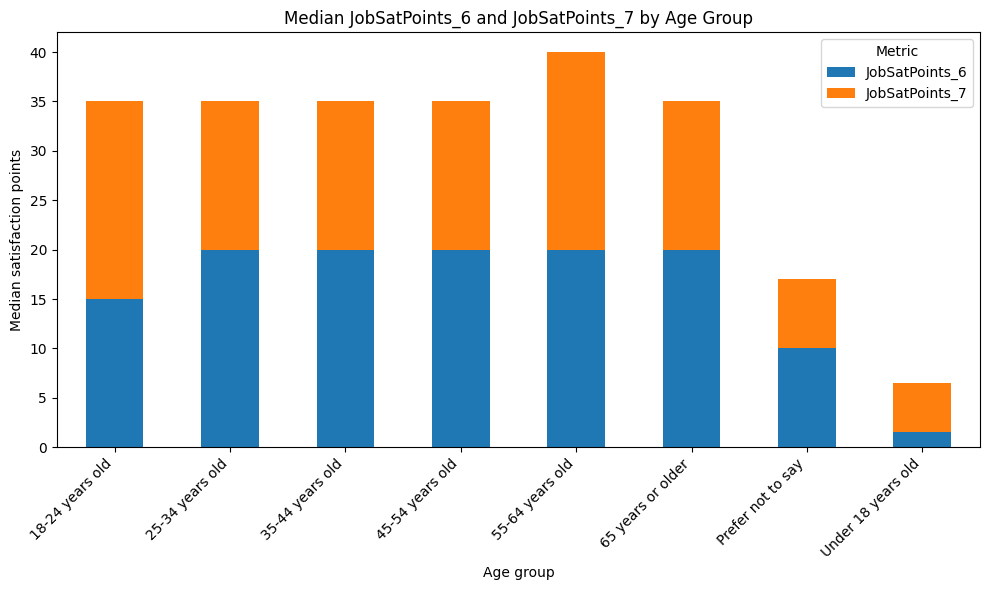

In [7]:
##Write your code here
# Stacked chart of median JobSatPoints_6 and JobSatPoints_7 for different Age groups
medians = df.groupby('Age')[['JobSatPoints_6', 'JobSatPoints_7']].median()
print(medians)
medians.plot(kind='bar', stacked=True, figsize=(10, 6))
plt.title('Median JobSatPoints_6 and JobSatPoints_7 by Age Group')
plt.xlabel('Age group')
plt.ylabel('Median satisfaction points')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Metric')
plt.tight_layout()
plt.show()

##### Stacked Chart of `JobSatPoints_6` and `JobSatPoints_7` for Employment Status


Create a stacked chart to compare job satisfaction (`JobSatPoints_6` and `JobSatPoints_7`) across different employment statuses. This will show how satisfaction varies by employment type.


                                                    JobSatPoints_6  \
Employment                                                           
Employed, full-time                                           20.0   
Employed, full-time;Employed, part-time                       15.0   
Employed, full-time;Independent contractor, fre...            15.0   
Employed, full-time;Independent contractor, fre...            20.0   
Employed, full-time;Independent contractor, fre...             NaN   
...                                                            ...   
Student, full-time;Student, part-time;Employed,...             0.0   
Student, full-time;Student, part-time;Retired                  NaN   
Student, part-time                                             NaN   
Student, part-time;Employed, part-time                        15.0   
Student, part-time;Retired                                     NaN   

                                                    JobSatPoints_7  
Employment          

C:\Users\Jerome\AppData\Local\Temp\ipykernel_9300\2315512566.py:11: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


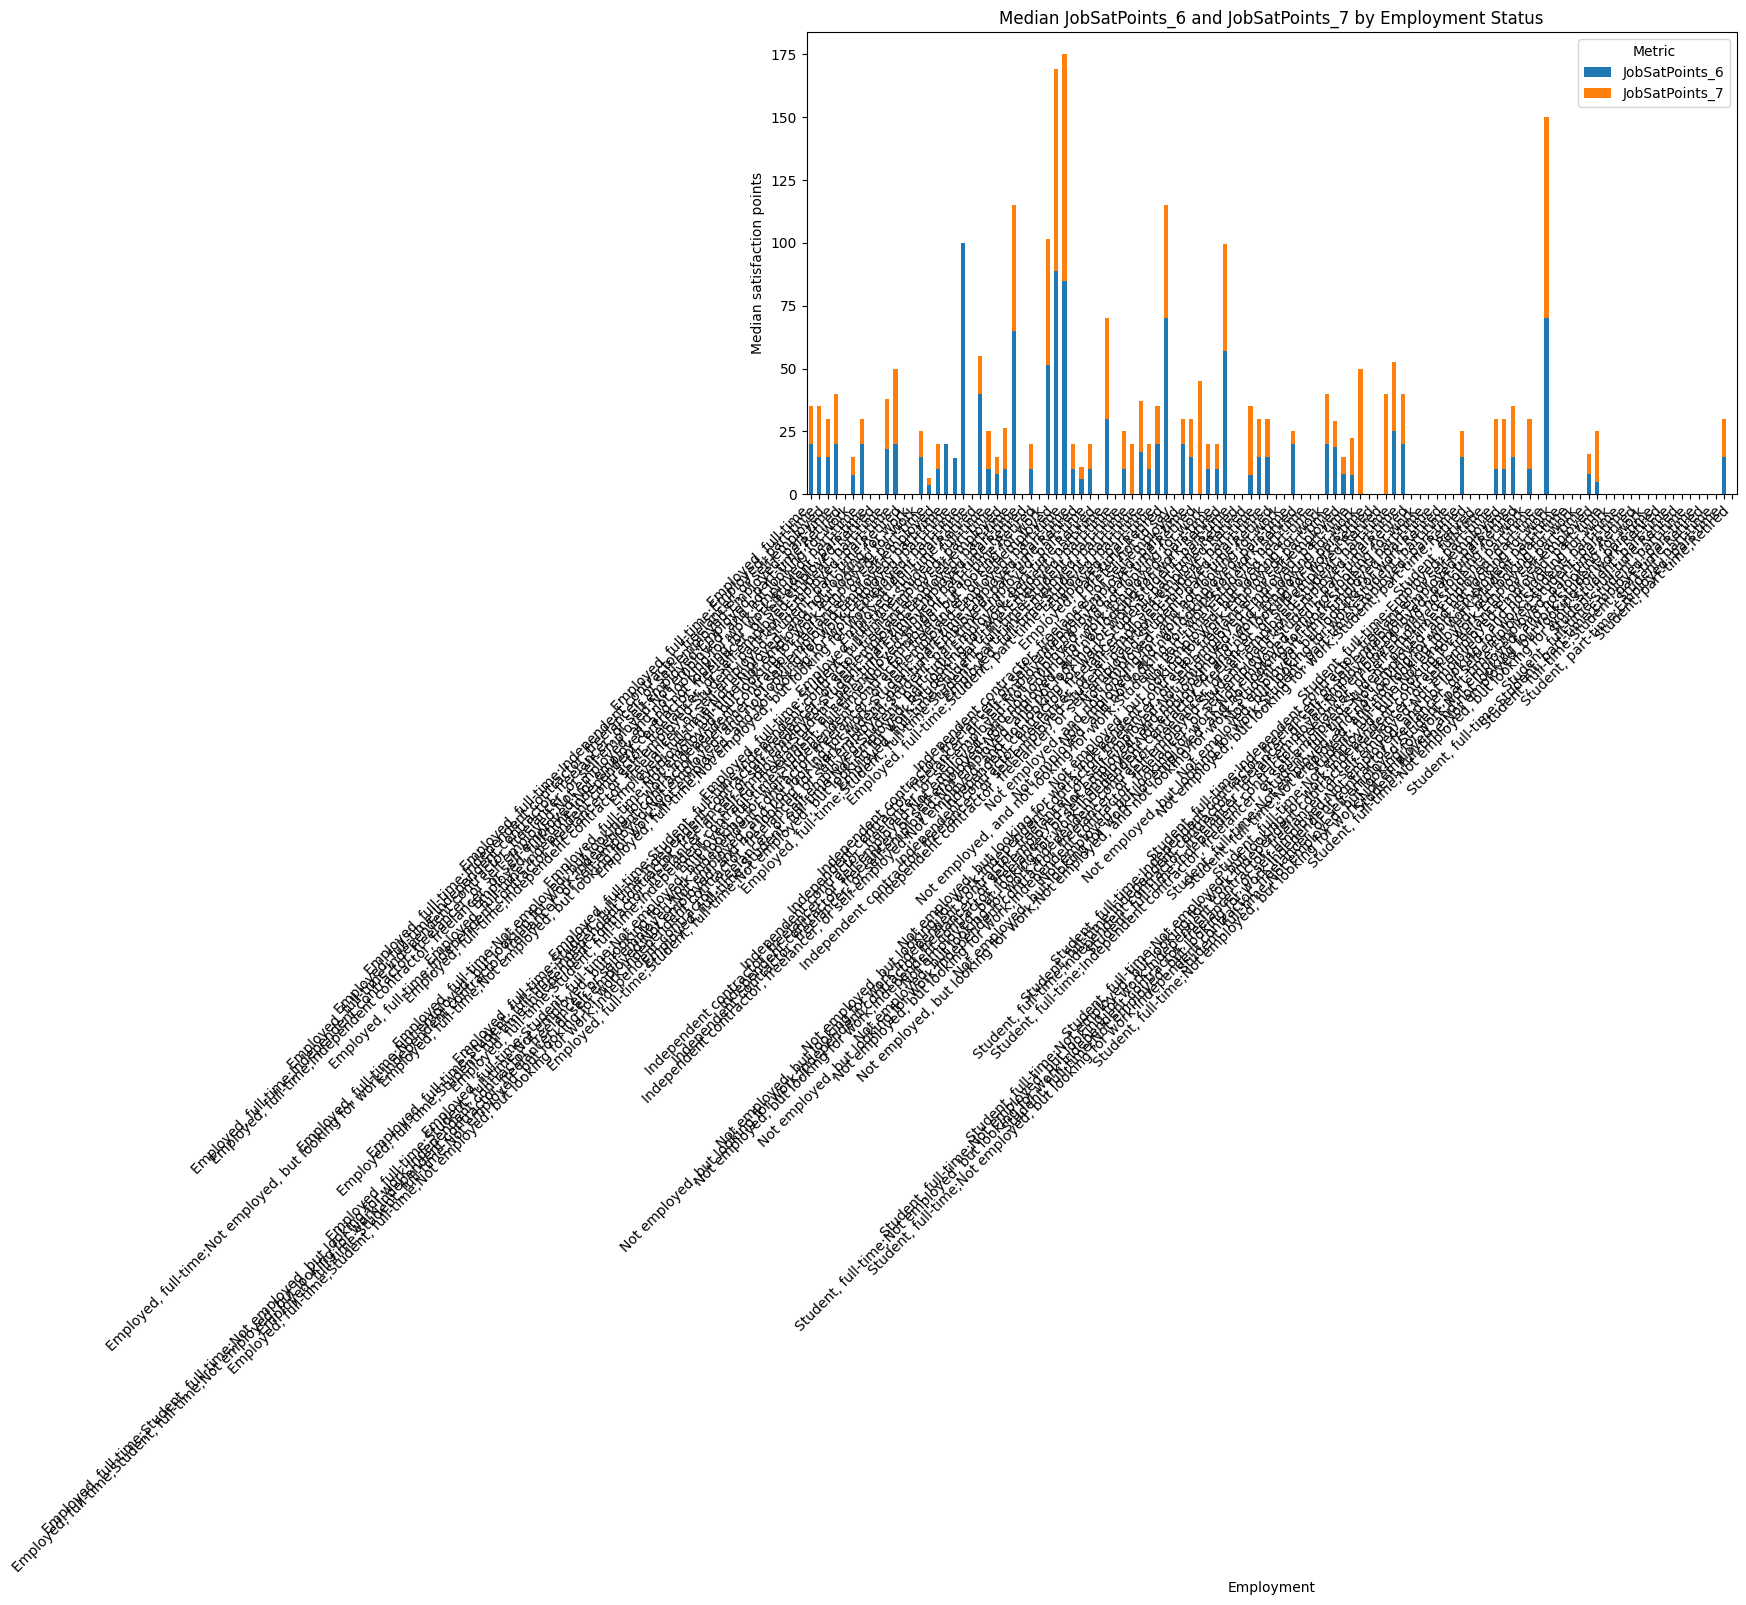

In [8]:
##Write your code here
# Stacked chart of JobSatPoints_6 and JobSatPoints_7 for Employment status
medians = df.groupby('Employment')[['JobSatPoints_6', 'JobSatPoints_7']].median()
print(medians)
medians.plot(kind='bar', stacked=True, figsize=(12, 6))
plt.title('Median JobSatPoints_6 and JobSatPoints_7 by Employment Status')
plt.xlabel('Employment')
plt.ylabel('Median satisfaction points')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Metric')
plt.tight_layout()
plt.show()

### Task 2: Stacked Chart for Compensation and Job Satisfaction by Age Group


##### This stacked chart visualizes the composition of compensation (`ConvertedCompYearly`) and job satisfaction (`JobSatPoints_6`) specifically for respondents aged 30-35.


                 ConvertedCompYearly  JobSatPoints_6
Age                                                 
25-34 years old              59825.0            20.0
35-44 years old              84796.0            20.0


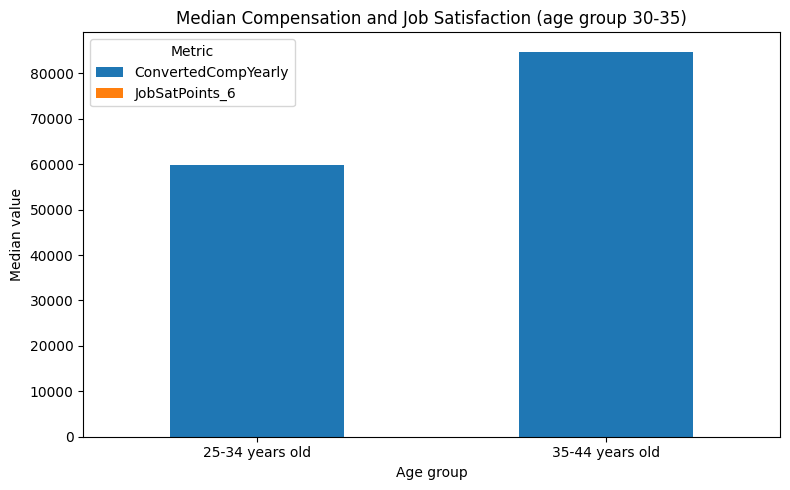

In [9]:
##Write your code here
# Stacked chart of compensation and job satisfaction for age group 30-35
age_groups = ['25-34 years old', '35-44 years old']
subset = df[df['Age'].isin(age_groups)]

medians = subset.groupby('Age')[['ConvertedCompYearly', 'JobSatPoints_6']].median()
print(medians)
medians.plot(kind='bar', stacked=True, figsize=(8, 5))
plt.title('Median Compensation and Job Satisfaction (age group 30-35)')
plt.xlabel('Age group')
plt.ylabel('Median value')
plt.xticks(rotation=0)
plt.legend(title='Metric')
plt.tight_layout()
plt.show()

##### Stacked Chart of Median Compensation and Job Satisfaction Across Age Group


Compare the median compensation and job satisfaction metrics across different age groups. This helps visualize how compensation and satisfaction levels differ by age.


                    ConvertedCompYearly  JobSatPoints_6
Age                                                    
18-24 years old                 25000.0            15.0
25-34 years old                 59825.0            20.0
35-44 years old                 84796.0            20.0
45-54 years old                 99099.0            20.0
55-64 years old                109691.0            20.0
65 years or older              106000.0            20.0
Prefer not to say              140000.0            10.0
Under 18 years old               7626.5             1.5


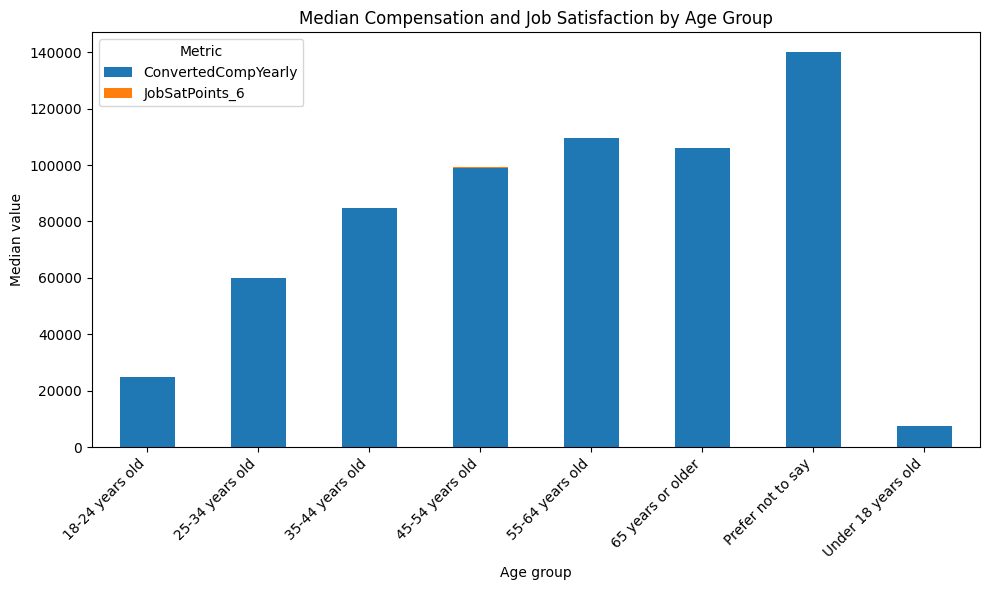

In [10]:
##Write your code here
# Stacked chart of median compensation and job satisfaction across age groups
medians = df.groupby('Age')[['ConvertedCompYearly', 'JobSatPoints_6']].median()
print(medians)
medians.plot(kind='bar', stacked=True, figsize=(10, 6))
plt.title('Median Compensation and Job Satisfaction by Age Group')
plt.xlabel('Age group')
plt.ylabel('Median value')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Metric')
plt.tight_layout()
plt.show()

### Task 3: Comparing Data Using Stacked Charts


##### 1. Stacked Chart of Preferred Databases by Age Group




Visualize the top databases that respondents from different age groups wish to learn. Create a stacked chart to show the proportion of each database in each age group.


Database            MongoDB  MySQL  PostgreSQL  Redis  SQLite
Age                                                          
18-24 years old        3027   3077        5113   2235    3052
25-34 years old        4363   4465        9523   4542    4897
35-44 years old        2140   2536        5769   2779    3060
45-54 years old         773   1125        2201    865    1293
55-64 years old         234    471         724    176     493
65 years or older        45    143         108     20     131
Prefer not to say        26     41          61     21      55
Under 18 years old      374    411         506    209     508


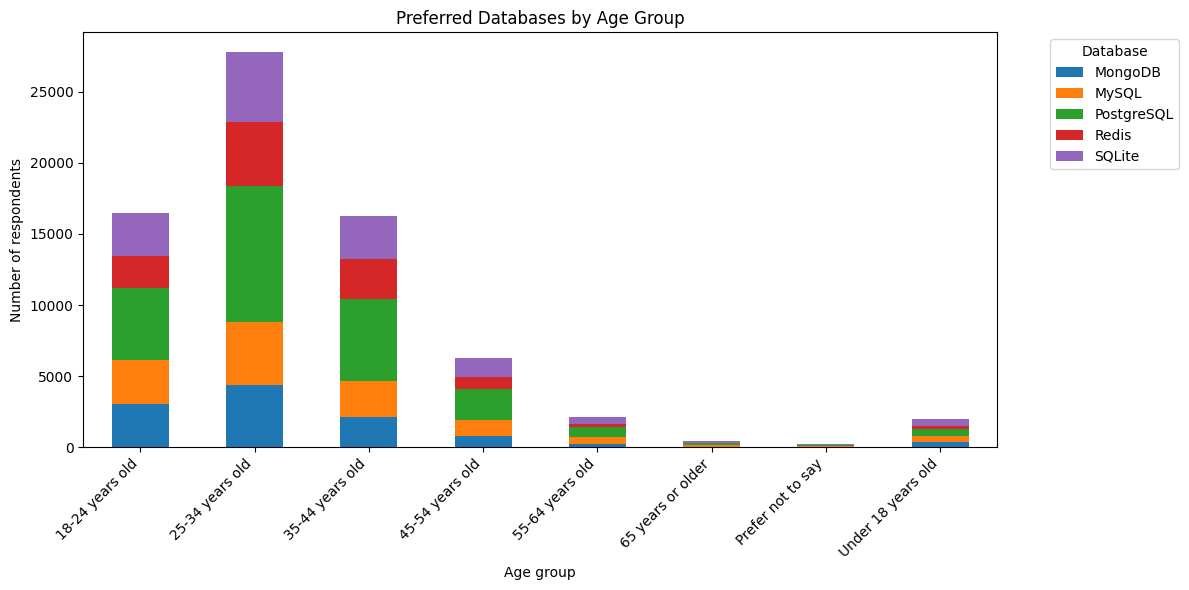

In [11]:
##Write your code here
# Stacked chart of preferred databases by age group (top 5 databases)
top_dbs = df['DatabaseWantToWorkWith'].dropna().str.split(';').explode().value_counts().head(5).index.tolist()

subset = df[df['DatabaseWantToWorkWith'].notna()].copy()
subset['Database'] = subset['DatabaseWantToWorkWith'].str.split(';')
exploded = subset.explode('Database')
exploded = exploded.reset_index(drop=True)
exploded = exploded[exploded['Database'].isin(top_dbs)]

ct = pd.crosstab(exploded['Age'], exploded['Database'])
print(ct)
ct.plot(kind='bar', stacked=True, figsize=(12, 6))
plt.title('Preferred Databases by Age Group')
plt.xlabel('Age group')
plt.ylabel('Number of respondents')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Database', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

##### 2. Stacked Chart of Employment Type by Job Satisfaction


Analyze the distribution of employment types within each job satisfaction level using a stacked chart. This will provide insights into how employment types are distributed across various satisfaction ratings.


Employment      Employed, full-time  Employed, full-time;Employed, part-time  \
JobSatPoints_6                                                                 
0.0                            5989                                       39   
1.0                              32                                        0   
2.0                              32                                        0   
3.0                              29                                        0   
4.0                              21                                        0   
...                             ...                                      ...   
96.0                              1                                        0   
97.0                              1                                        0   
98.0                              4                                        0   
99.0                             15                                        0   
100.0                           732     

C:\Users\Jerome\AppData\Local\Temp\ipykernel_9300\1811677337.py:11: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


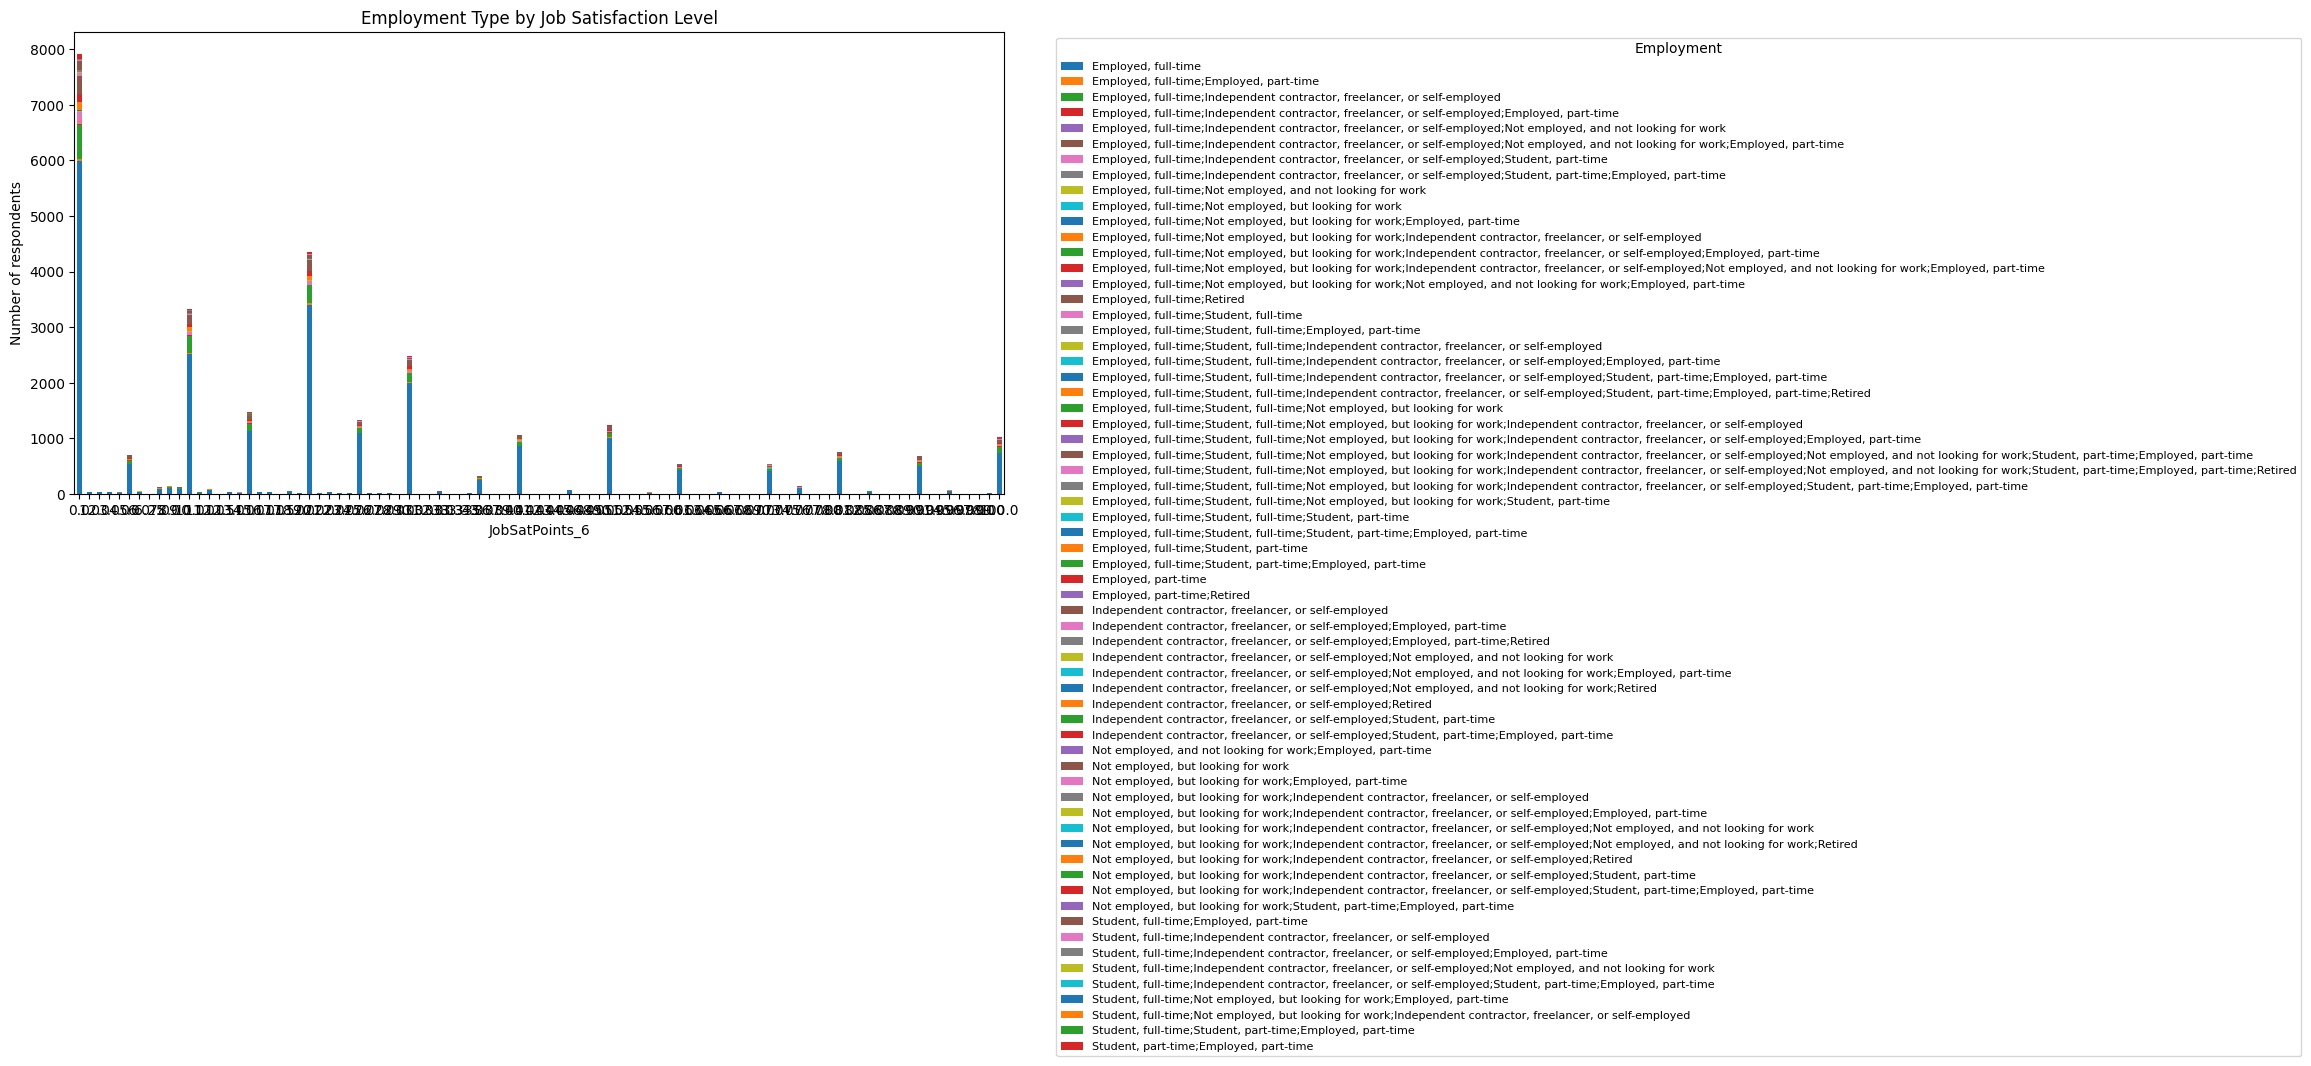

In [12]:
##Write your code here
# Stacked chart of employment type by job satisfaction level
ct = pd.crosstab(df['JobSatPoints_6'], df['Employment'])
print(ct)
ct.plot(kind='bar', stacked=True, figsize=(12, 6))
plt.title('Employment Type by Job Satisfaction Level')
plt.xlabel('JobSatPoints_6')
plt.ylabel('Number of respondents')
plt.xticks(rotation=0)
plt.legend(title='Employment', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

### Task 4: Exploring Technology Preferences Using Stacked Charts


##### 1. Stacked Chart for Preferred Programming Languages by Age Group


Analyze how programming language preferences (`LanguageAdmired`) vary across age groups.


Language            HTML/CSS  JavaScript  Python   SQL  TypeScript
Age                                                               
18-24 years old         4523        4728    5157  4004        3567
25-34 years old         6937        7936    7431  7516        6696
35-44 years old         4580        5161    4239  5055        3766
45-54 years old         1800        2051    1802  2382        1146
55-64 years old          715         819     741  1028         320
65 years or older        169         170     194   204          38
Prefer not to say         97          85     105    63          41
Under 18 years old      1030         919    1105   440         505


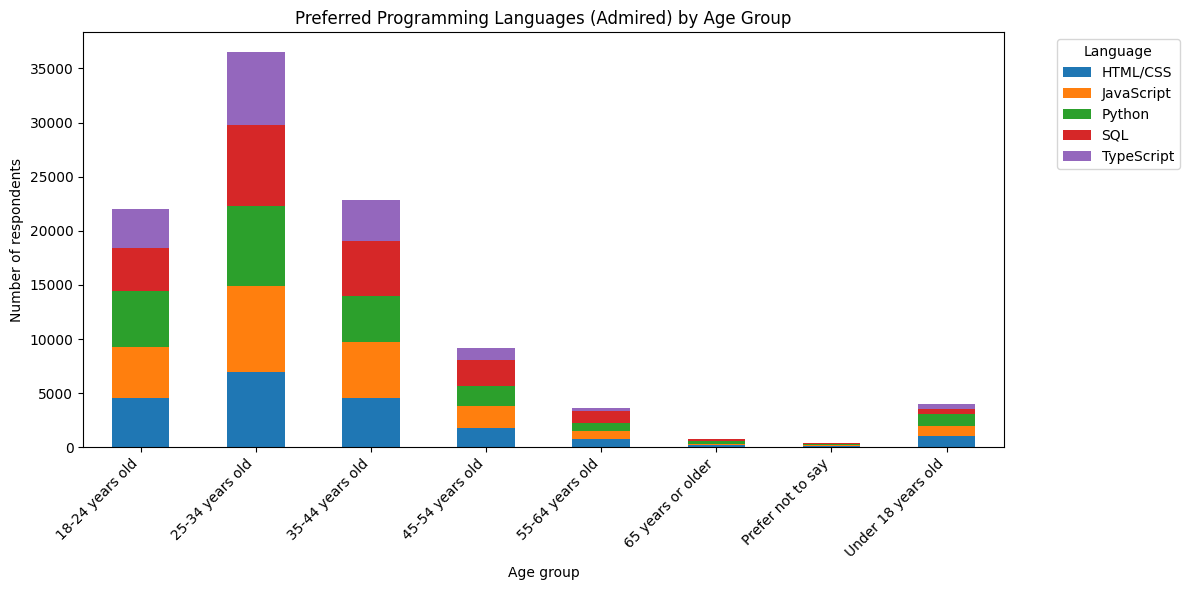

In [13]:
##Write your code here
# Stacked chart of preferred programming languages (LanguageAdmired) by age group
top_langs = df['LanguageAdmired'].dropna().str.split(';').explode().value_counts().head(5).index.tolist()

subset = df[df['LanguageAdmired'].notna()].copy()
subset['Language'] = subset['LanguageAdmired'].str.split(';')
exploded = subset.explode('Language')
exploded = exploded.reset_index(drop=True)
exploded = exploded[exploded['Language'].isin(top_langs)]

ct = pd.crosstab(exploded['Age'], exploded['Language'])
print(ct)
ct.plot(kind='bar', stacked=True, figsize=(12, 6))
plt.title('Preferred Programming Languages (Admired) by Age Group')
plt.xlabel('Age group')
plt.ylabel('Number of respondents')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Language', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

##### 2. Stacked Chart for Technology Adoption by Employment Type


Explore how admired platforms (`PlatformAdmired`) differ across employment types (e.g., full-time, freelance)


Platform                                            Amazon Web Services (AWS)  \
Employment                                                                      
Employed, full-time                                                      9584   
Employed, full-time;Employed, part-time                                    58   
Employed, full-time;Independent contractor, fre...                       1144   
Employed, full-time;Independent contractor, fre...                         67   
Employed, full-time;Independent contractor, fre...                          1   
...                                                                       ...   
Student, full-time;Student, part-time;Employed,...                          2   
Student, full-time;Student, part-time;Retired                               0   
Student, part-time                                                         27   
Student, part-time;Employed, part-time                                     55   
Student, part-time;Retired  

C:\Users\Jerome\AppData\Local\Temp\ipykernel_9300\1067979128.py:19: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


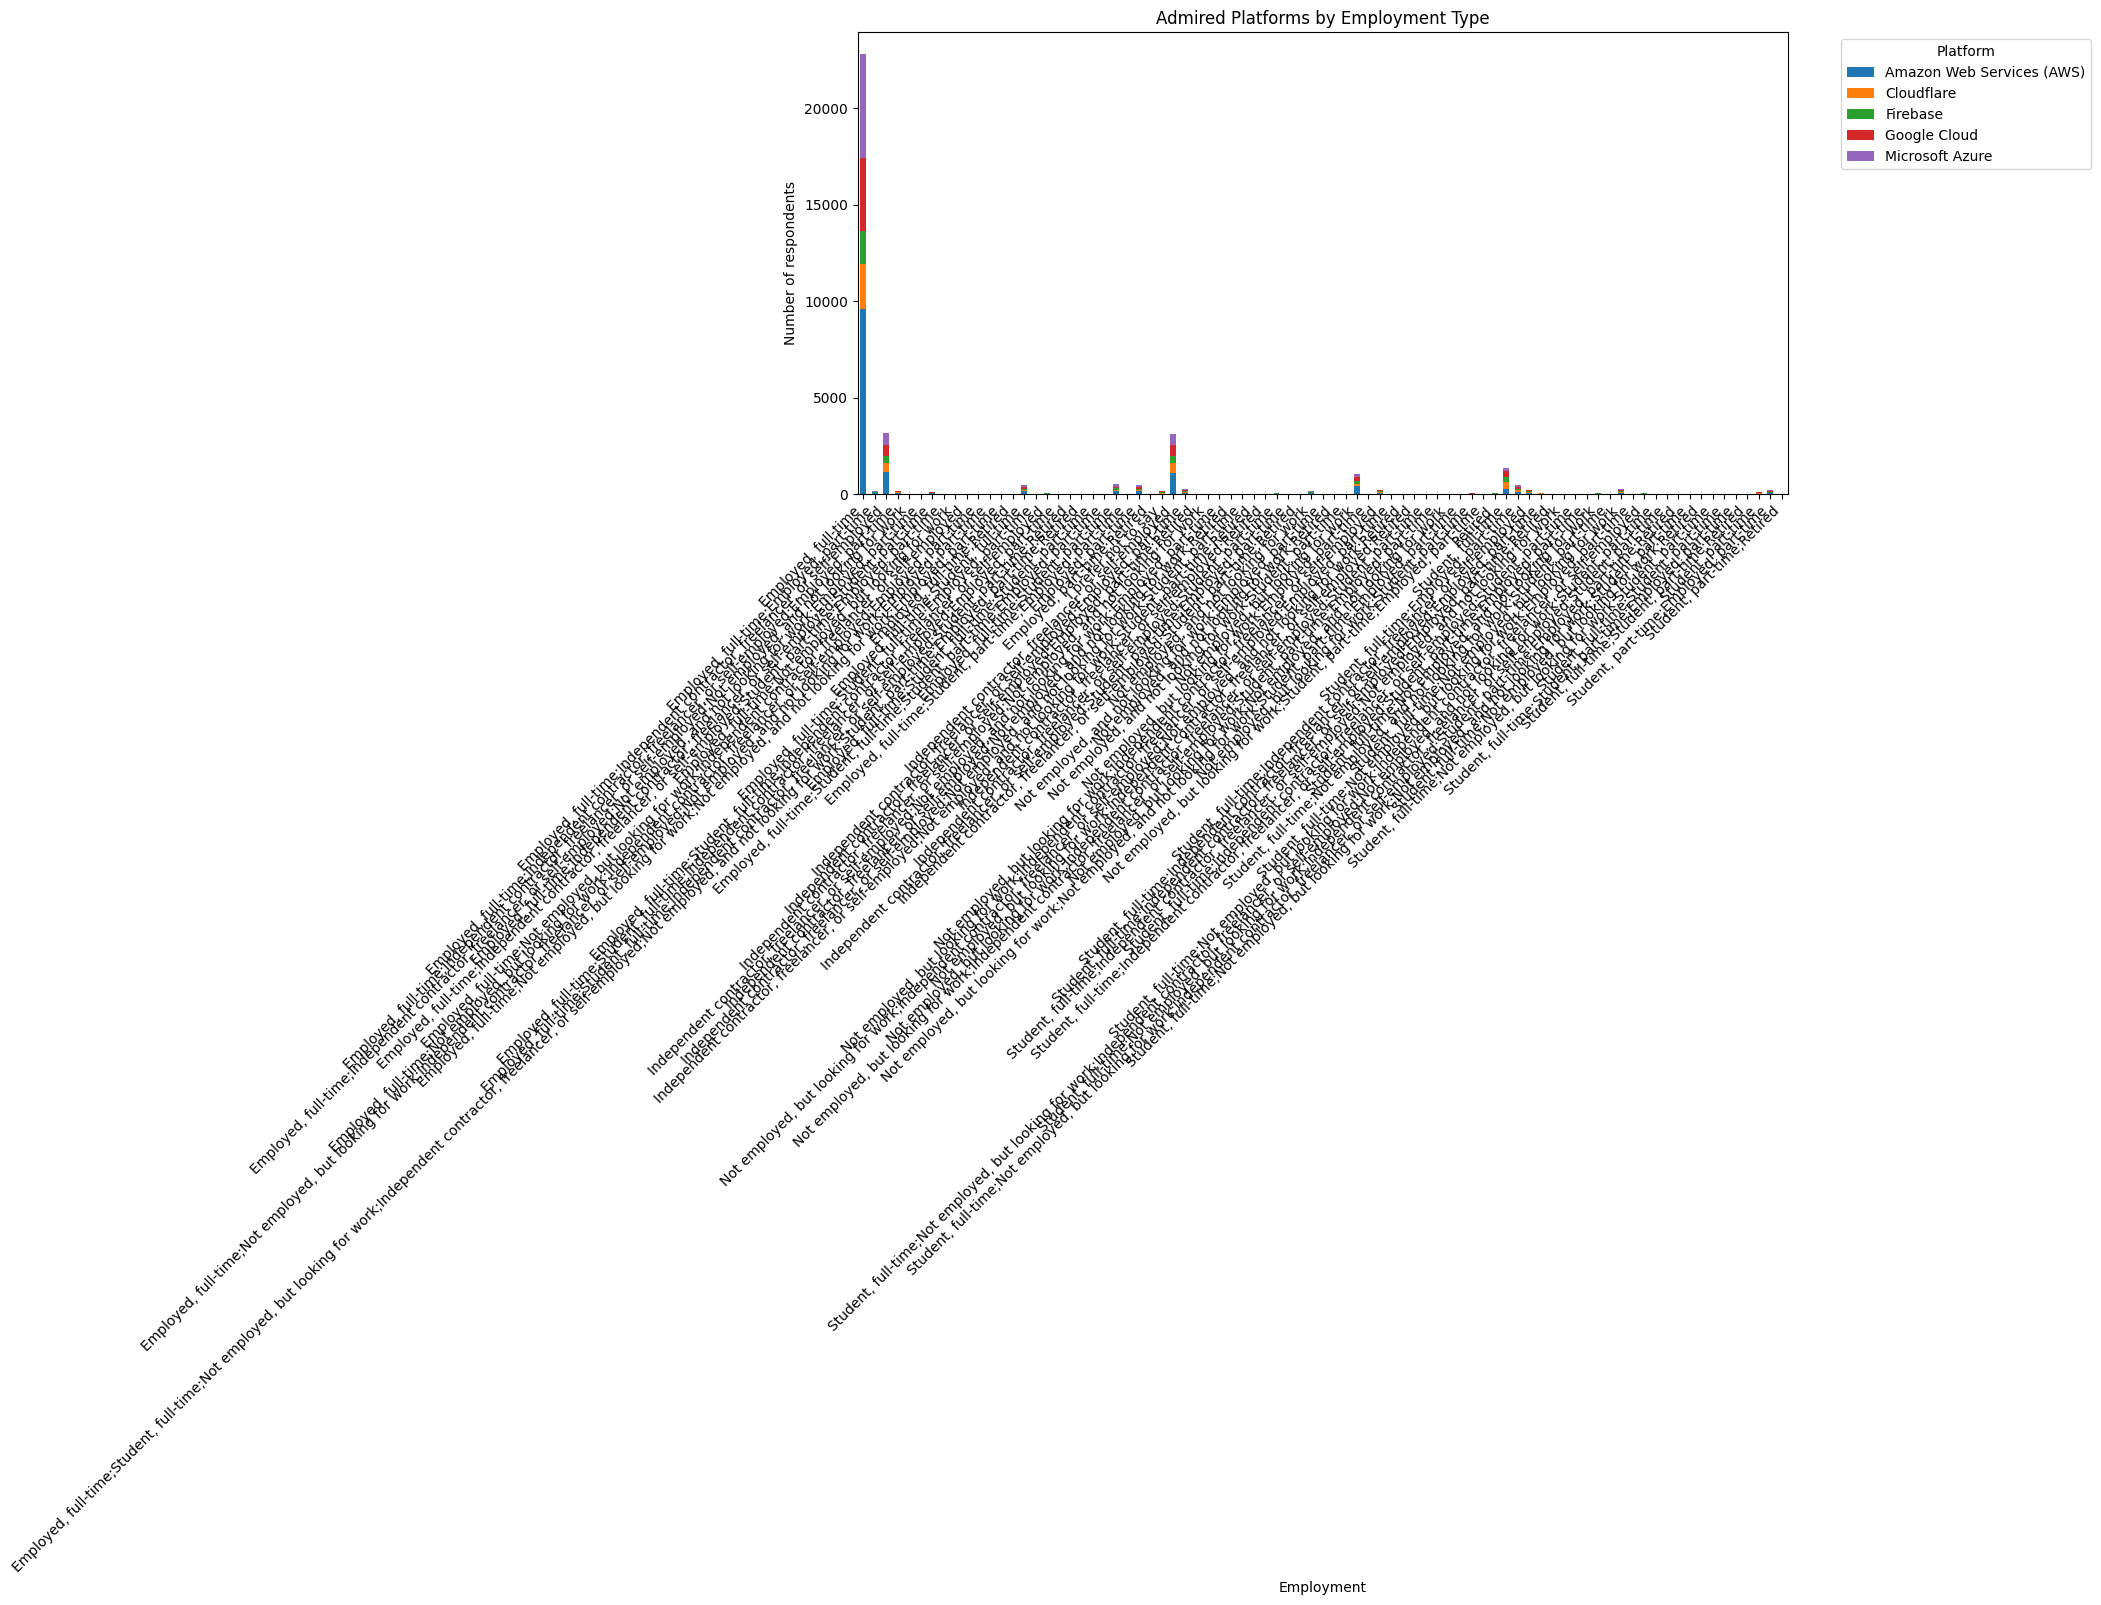

In [14]:
##Write your code here
# Stacked chart of admired platforms (PlatformAdmired) by employment type
top_platforms = df['PlatformAdmired'].dropna().str.split(';').explode().value_counts().head(5).index.tolist()

subset = df[df['PlatformAdmired'].notna()].copy()
subset['Platform'] = subset['PlatformAdmired'].str.split(';')
exploded = subset.explode('Platform')
exploded = exploded.reset_index(drop=True)
exploded = exploded[exploded['Platform'].isin(top_platforms)]

ct = pd.crosstab(exploded['Employment'], exploded['Platform'])
print(ct)
ct.plot(kind='bar', stacked=True, figsize=(12, 6))
plt.title('Admired Platforms by Employment Type')
plt.xlabel('Employment')
plt.ylabel('Number of respondents')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Platform', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Final Step: Review


In this lab, you focused on using stacked charts to understand the composition and comparison within the dataset. Stacked charts provided insights into job satisfaction, compensation, and preferred databases across age groups and employment types.


## Summary


After completing this lab, you will be able to:

- Use stacked charts to analyze the composition of data across categories, such as job satisfaction and compensation by age group.

- Compare data across different dimensions using stacked charts, enhancing your ability to communicate complex relationships in the data.

- Visualize distributions across multiple categories, such as employment type by satisfaction, to gain a deeper understanding of patterns within the dataset.


## Author:
Ayushi Jain


### Other Contributors:
- Rav Ahuja
- Lakshmi Holla
- Malika


<!--
## Change Log
|Date (YYYY-MM-DD)|Version|Changed By|Change Description|
|-|-|-|-|
|2024-10-28|1.2|Madhusudhan Moole|Updated lab|
|2024-10-16|1.1|Madhusudhan Moole|Updated lab|
|2024-10-15|1.0|Raghul Ramesh|Created lab|
--!>


Copyright © IBM Corporation. All rights reserved.
